In [2]:
# Check that GPU is used
import tensorflow as tf
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [35]:
from PIL import Image
import os
import numpy as np

# Define the folders where your data is stored
train_folder = 'chest_xray/train'
test_folder = 'chest_xray/test'
val_folder = 'chest_xray/val'

# Define the subfolders within each folder where the images are stored
subfolders = ['NORMAL', 'VIRUS', 'BACTERIA']

# Define the size of the images you want to resize your images to
img_width, img_height = 128, 128

In [4]:
def split_virus_bacteria_pneumonia(folder):
    temp_subfolders = ['NORMAL', 'VIRUS', 'BACTERIA', 'PNEUMONIA']

    # Create the subfolders if they don't exist
    for subfolder in subfolders:
        if not os.path.exists(os.path.join(folder, subfolder)):
            os.makedirs(os.path.join(folder, subfolder))

    # Move the images to the corresponding subfolder
    for subfolder in temp_subfolders:
        subfolder_path = os.path.join(folder, subfolder)
        if subfolder == 'PNEUMONIA':
            for filename in os.listdir(subfolder_path):
                if 'virus' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'VIRUS', filename))
                elif 'bacteria' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'BACTERIA', filename))
        else:
            for filename in os.listdir(subfolder_path):
                os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, subfolder, filename))

In [ ]:
# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(train_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(test_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(val_folder)

In [5]:
# Function to load and resize images from a folder
def load_images_from_folder(folder, limit_per_subfolder=None):
    X = []
    y = []
    for subfolder in subfolders:
        folder_path = os.path.join(folder, subfolder)
        if limit_per_subfolder:
            # Get amount of random filenames from the folder
            filenames = np.random.choice(os.listdir(folder_path), limit_per_subfolder, replace=False)
        else:
            filenames = os.listdir(folder_path)
        for filename in filenames:
            img_path = os.path.join(folder_path, filename)
            img = Image.open(img_path)

            # Resize the image to the desired size
            img = img.resize((img_width, img_height))

            # Convert RGB image to grayscale
            img = img.convert('L')

            # Convert the image to a NumPy array and append it to X
            img = np.array(img)
            X.append(img)

            # Append the corresponding label to y
            y.append(subfolders.index(subfolder))

    X = np.array(X)
    y = np.array(y)
    return X, y

In [ ]:
# Generate augmented for the training set
from data_augmentation import generate_augmented_images
generate_augmented_images(train_folder, 'NORMAL', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'BACTERIA', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'VIRUS', image_size=(img_width, img_height))

In [6]:
# Load the training data
# Get min value between the number of normal images and the number of pneumonia images
train_folder = train_folder if train_folder.endswith('_augmented') else f"{train_folder}_augmented"
min_images = min(len(os.listdir(os.path.join(train_folder, subfolders[0]))), len(os.listdir(os.path.join(train_folder, subfolders[1]))), len(os.listdir(os.path.join(train_folder, subfolders[2]))))
X_train, y_train = load_images_from_folder(train_folder, min_images)

# Load the test data
X_test, y_test = load_images_from_folder(test_folder)

# Load the validation data
X_val, y_val = load_images_from_folder(val_folder)

In [7]:
# One-hot encode the labels
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
y_val = to_categorical(y_val)

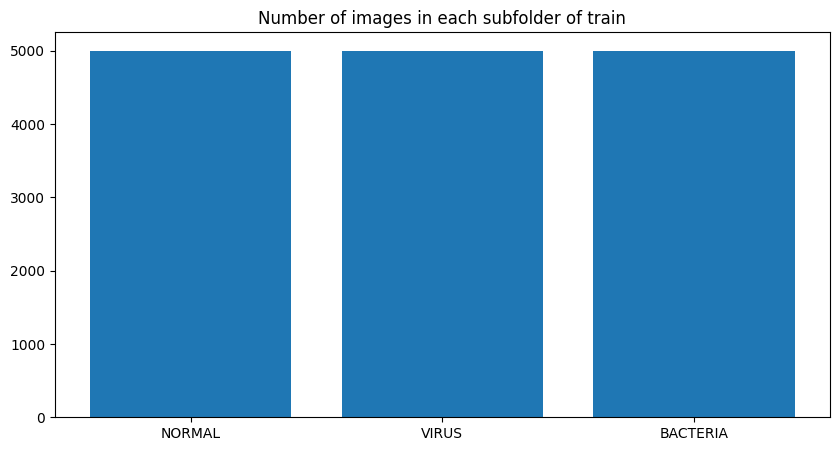

In [8]:
# Make a matplot figure to show how many images are in each subfolder of train
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [len(os.listdir(os.path.join(train_folder, subfolder))) for subfolder in subfolders])
plt.title('Number of images in each subfolder of train')
plt.show()

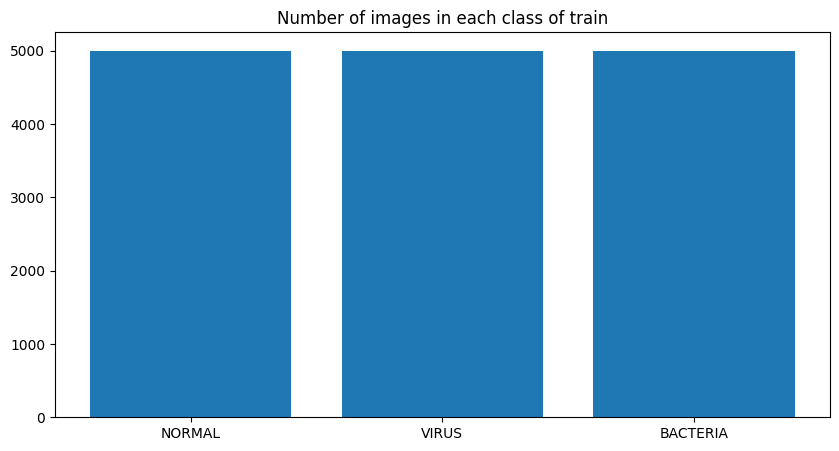

In [9]:
# Make a matplot figure to show how many images if each class in the training set considering it is hot-encoded
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [sum(y_train[:, i]) for i in range(len(subfolders))])
plt.title('Number of images in each class of train')
plt.show()

In [10]:
# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255
X_val = X_val.astype('float32') / 255

X_train = X_train.reshape(len(X_train), img_width, img_height, 1)
X_test = X_test.reshape(len(X_test), img_width, img_height, 1)
X_val = X_val.reshape(len(X_val), img_width, img_height, 1)

(128, 128, 1)


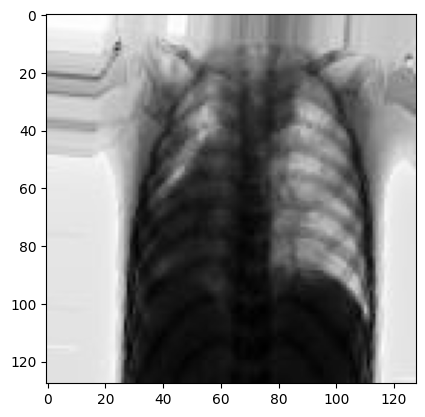

In [11]:
single_image = X_train[np.random.randint(len(X_train))]
print(single_image.shape)
plt.imshow(single_image, cmap='Greys')

In [12]:
# Define model metrics
from keras.metrics import AUC

metrics = [
    "accuracy",
    AUC(name='auc')
]

I0000 00:00:1747643486.588743   36829 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Define the model architecture
def create_model():
    model = Sequential()

    model.add(Conv2D(filters=32, kernel_size=(3,3), input_shape=(img_width, img_height, 1), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2)))

    model.add(Conv2D(filters=64, kernel_size=(3,3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2)))

    model.add(Conv2D(filters=128, kernel_size=(3,3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2)))

    model.add(Conv2D(filters=256, kernel_size=(3,3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2)))

    model.add(Flatten())

    model.add(Dense(256, activation="relu"))
    model.add(Dropout(0.5))

    model.add(Dense(128, activation="relu"))
    model.add(Dropout(0.5))

    model.add(Dense(3, activation="softmax"))

    # compile the model
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=metrics)

    return model

In [14]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)

In [15]:
# Cross validation
from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define the number of folds for cross-validation
n_splits = 10
epochs = 7
batch_size = 64

# Initialize KFold with the number of folds
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Define lists to store the evaluation scores for each fold
accuracy_scores = []
histories = []
models = []

# Iterate through each fold and train/evaluate the model
for train_idx, val_idx in kf.split(X_train, y_train):
    # Split the data into training and validation sets for this fold
    X_train_fold, y_train_fold = X_train[train_idx], y_train[train_idx]
    X_val_fold, y_val_fold = X_train[val_idx], y_train[val_idx]

    # Create an instance of ImageDataGenerator to generate your image data
    datagen = ImageDataGenerator()

    # Create generators for training and validation data
    train_generator = datagen.flow(x=X_train_fold, y=y_train_fold, batch_size=batch_size)
    valid_generator = datagen.flow(x=X_val_fold, y=y_val_fold, batch_size=batch_size)

    # Create instance of the model for this fold and train it
    model = create_model()

    # Train your model on the training data for this fold
    history = model.fit(train_generator, validation_data=valid_generator, epochs=epochs, verbose=1, callbacks=[early_stop])
    histories.append(history.history)

    models.append(model)


/home/atressel/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/7


/home/atressel/.local/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1747643496.447017   37226 service.cc:152] XLA service 0x7f900400fd60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1747643496.447068   37226 service.cc:160]   StreamExecutor device (0): NVIDIA RTX 1000 Ada Generation Laptop GPU, Compute Capability 8.9
2025-05-19 10:31:36.499527: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1747643496.758395   37226 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.3212 - auc: 0.5241 - loss: 1.1055 

I0000 00:00:1747643503.206286   37226 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.3386 - auc: 0.5123 - loss: 1.0975

2025-05-19 10:31:57.995192: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_150', 8 bytes spill stores, 8 bytes spill loads

2025-05-19 10:31:58.186936: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_150', 104 bytes spill stores, 104 bytes spill loads

2025-05-19 10:32:00.997494: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_157', 4 bytes spill stores, 4 bytes spill loads



211/211 ━━━━━━━━━━━━━━━━━━━━ 27s 90ms/step - accuracy: 0.3388 - auc: 0.5125 - loss: 1.0973 - val_accuracy: 0.5980 - val_auc: 0.7924 - val_loss: 0.8509
Epoch 2/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.6082 - auc: 0.7955 - loss: 0.8419 - val_accuracy: 0.7033 - val_auc: 0.8748 - val_loss: 0.6730
Epoch 3/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.6851 - auc: 0.8570 - loss: 0.7109 - val_accuracy: 0.7187 - val_auc: 0.8807 - val_loss: 0.6492
Epoch 4/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.7159 - auc: 0.8845 - loss: 0.6343 - val_accuracy: 0.7567 - val_auc: 0.9098 - val_loss: 0.5697
Epoch 5/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.7396 - auc: 0.9012 - loss: 0.5897 - val_accuracy: 0.7747 - val_auc: 0.9203 - val_loss: 0.5322
Epoch 6/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/step - accuracy: 0.7571 - auc: 0.9163 - loss: 0.5384 - val_accuracy: 0.7873 - val_auc: 0.9275 - val_loss: 0.5048
Epoch 7/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 42ms/st

In [16]:
# Get accuracy scores for each fold (train and validation)
loss = []
acc = []
val_loss = []
val_acc = []

for history in histories:
    loss.append(np.mean(history["loss"]))
    acc.append(np.mean(history["accuracy"]))
    val_loss.append(np.mean(history["val_loss"]))
    val_acc.append(np.mean(history["val_accuracy"]))

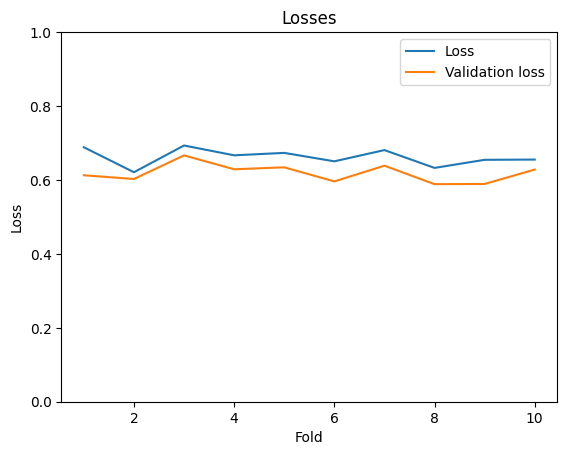

In [17]:
# Plot loss and validation loss per fold
import matplotlib.pyplot as plt
plt.title('Losses')
plt.plot(range(1, len(loss)+1), loss, label='Loss')
plt.plot(range(1, len(val_loss)+1), val_loss, label='Validation loss')
plt.ylim(0.0, 1.0)
plt.xlabel('Fold')
plt.ylabel('Loss')
plt.legend()
plt.show()

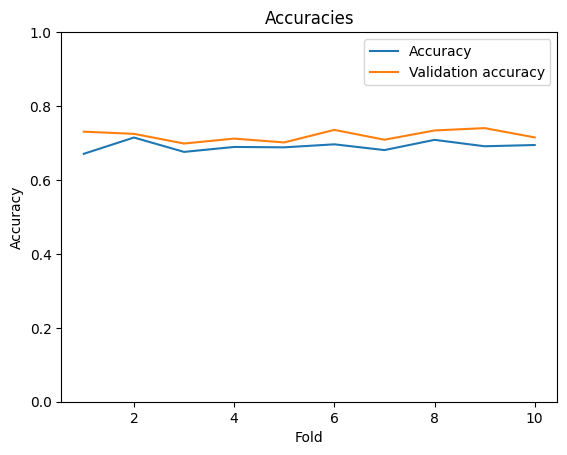

In [18]:
# Plot accuracies and validation accuracies per fold
import matplotlib.pyplot as plt
plt.title('Accuracies')
plt.plot(range(1, len(acc)+1), acc, label='Accuracy')
plt.plot(range(1, len(val_acc)+1), val_acc, label='Validation accuracy')
plt.ylim(0.0, 1.0)
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [19]:
# Train a final model with same parameters and save it
train_generator = datagen.flow(x=X_train, y=y_train, batch_size=batch_size)
valid_generator = datagen.flow(x=X_val, y=y_val, batch_size=batch_size)
model = create_model()
history = model.fit(train_generator, validation_data=valid_generator, epochs=epochs, verbose=1, callbacks=[early_stop])
model.save('cnn.h5')

Epoch 1/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.3779 - auc: 0.6807 - loss: 1.0858

2025-05-19 10:44:00.700881: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_150', 128 bytes spill stores, 128 bytes spill loads



235/235 ━━━━━━━━━━━━━━━━━━━━ 20s 69ms/step - accuracy: 0.3782 - auc: 0.6807 - loss: 1.0857 - val_accuracy: 0.2500 - val_auc: 0.6167 - val_loss: 1.0948
Epoch 2/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.6218 - auc: 0.8081 - loss: 0.8177 - val_accuracy: 0.3056 - val_auc: 0.5677 - val_loss: 1.2454
Epoch 3/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.7023 - auc: 0.8750 - loss: 0.6625 - val_accuracy: 0.2778 - val_auc: 0.6215 - val_loss: 1.1091
Epoch 4/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.7336 - auc: 0.9000 - loss: 0.5917 - val_accuracy: 0.3333 - val_auc: 0.6076 - val_loss: 1.2221
Epoch 5/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.7510 - auc: 0.9093 - loss: 0.5654 - val_accuracy: 0.3333 - val_auc: 0.6508 - val_loss: 1.1167
Epoch 6/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.7711 - auc: 0.9216 - loss: 0.5225 - val_accuracy: 0.3889 - val_auc: 0.6688 - val_loss: 1.1728
Epoch 7/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 4

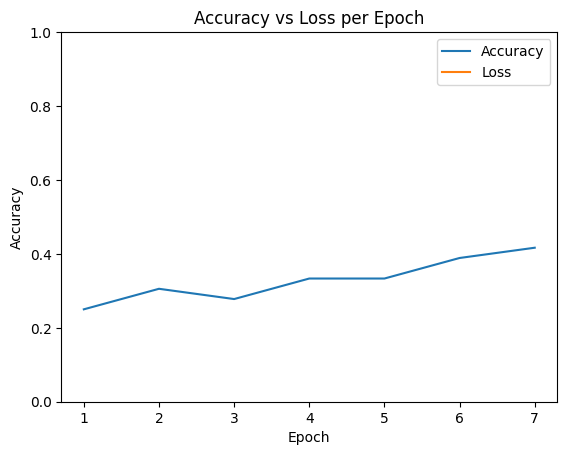

In [20]:
# Plot val accuracy and val loss of the trained model
import matplotlib.pyplot as plt
plt.title('Accuracy vs Loss per Epoch')
plt.plot(range(1, len(history.history["val_accuracy"])+1), history.history["val_accuracy"], label='Accuracy')
plt.plot(range(1, len(history.history["val_loss"])+1), history.history["val_loss"], label='Loss')
plt.ylim(0.0, 1.0)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [21]:
# Make predictions on the test set
y_pred_test = model.predict(X_test)
y_pred_test = np.where(y_pred_test >= 0.5, 1, 0)

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 89ms/step


In [22]:
# convert one-hot encoded y_test to class labels
y_test_labels = np.argmax(y_test, axis=1)

# convert y_pred_test to class labels
y_pred_labels = np.argmax(y_pred_test, axis=1)

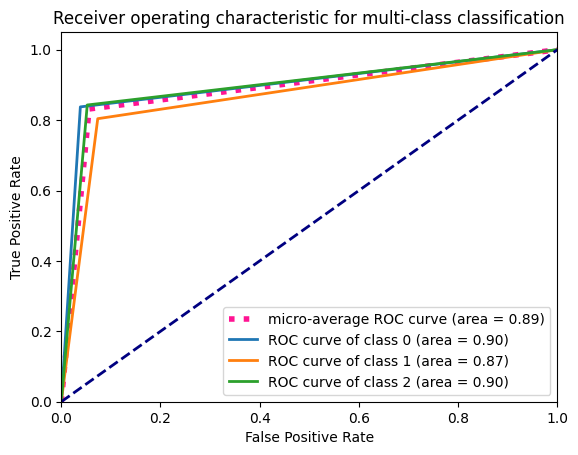

In [23]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Compute ROC curve and AUC score for each class
fpr = {}
tpr = {}
roc_auc = {}
for i in range(len(subfolders)):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_pred_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and AUC score
fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_pred_test.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC curve for each class and show AUC score on the plot
plt.figure()
lw = 2
plt.plot(fpr["micro"], tpr["micro"], color='deeppink', linestyle=':', linewidth=4, label='micro-average ROC curve (area = {0:0.2f})'.format(roc_auc["micro"]))
for i in range(len(subfolders)):
    plt.plot(fpr[i], tpr[i], lw=lw, label='ROC curve of class {0} (area = {1:0.2f})'.format(i, roc_auc[i]))

# Plot random guess line
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

# Set plot title and labels
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver operating characteristic for multi-class classification')
plt.legend(loc="lower right")
plt.show()


In [24]:
from sklearn.metrics import confusion_matrix
# compute confusion matrix
cm = confusion_matrix(y_test_labels, y_pred_labels)
print(cm)

[[210  22   2]
 [ 11 119  18]
 [ 25  13 204]]


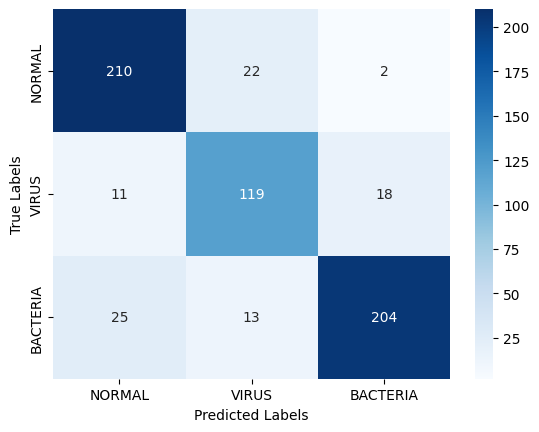

In [25]:
# Plot the confusion matrix
class_names = subfolders
import seaborn as sns
sns.heatmap(cm, annot=True, fmt='g', cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [26]:
# Compute the classification report for test set
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_test, target_names=class_names))

              precision    recall  f1-score   support

      NORMAL       0.93      0.84      0.88       234
       VIRUS       0.77      0.80      0.79       148
    BACTERIA       0.91      0.84      0.88       242

   micro avg       0.88      0.83      0.86       624
   macro avg       0.87      0.83      0.85       624
weighted avg       0.88      0.83      0.86       624
 samples avg       0.83      0.83      0.83       624



/home/atressel/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


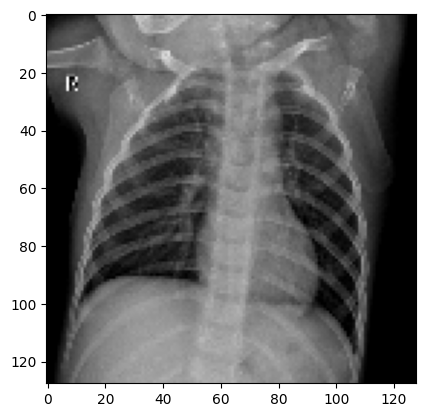

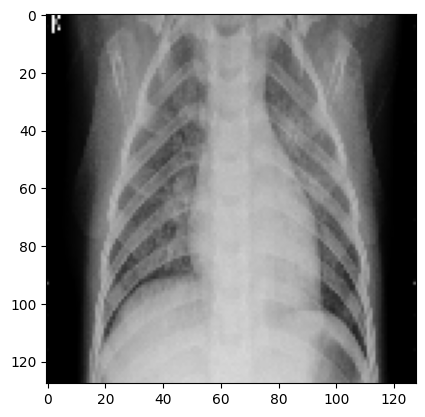

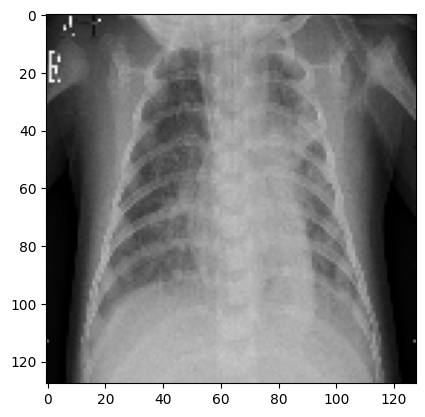

In [85]:
# Heatmaps and Grad-CAM
from cam import get_img_array
import cv2
import matplotlib.pyplot as plt 

images = [
    {
            "path": "./chest_xray/val/NORMAL/NORMAL2-IM-1442-0001.jpeg",
            "array": get_img_array("./chest_xray/val/NORMAL/NORMAL2-IM-1442-0001.jpeg", size=(256, 256))  # par exemple

    },
    {
        "path": "./chest_xray/val/VIRUS/person83_virus_156.jpeg",
        "array": get_img_array("./chest_xray/val/VIRUS/person83_virus_156.jpeg", size=(256, 256))  # par exemple

    },
    {
        "path": "./chest_xray/val/BACTERIA/person1946_bacteria_4874.jpeg",
        "array": get_img_array("./chest_xray/val/BACTERIA/person1946_bacteria_4874.jpeg", size=(256, 256))  # par exemple
    },
]

for image in images:
    image_temp = cv2.imread(image["path"])
    image_temp = cv2.cvtColor(image_temp, cv2.COLOR_RGB2GRAY)
    image_temp = cv2.resize(image_temp, (img_width, img_height))

    plt.imshow(image_temp, cmap=plt.cm.gray)
    plt.show()
    
    image["array"] = get_img_array(image["path"], size=(img_width, img_height))
    

In [99]:
# Remove last layer's softmax
model.layers[-1].activation = None

# import os
# os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

In [100]:
# Print model summary to get last max pooling layer name
print(model.summary())

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_40 (Conv2D)              │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_40 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_41 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_42 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_43 (MaxPooling2D) │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,342,027 (31.82 MB)

 Trainable params: 2,780,675 (10.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,561,352 (21.21 MB)

None


In [111]:
for layer in model.layers:
    print(f"- {layer.name} ({layer.__class__.__name__})")

# Vérification de la dernière couche de convolution
last_conv_layer = model.get_layer("max_pooling2d_43")
print(f"\nDernière couche de convolution : {last_conv_layer.name}")
last_conv_layer_name = last_conv_layer.name

- conv2d_40 (Conv2D)
- max_pooling2d_40 (MaxPooling2D)
- conv2d_41 (Conv2D)
- max_pooling2d_41 (MaxPooling2D)
- conv2d_42 (Conv2D)
- max_pooling2d_42 (MaxPooling2D)
- conv2d_43 (Conv2D)
- max_pooling2d_43 (MaxPooling2D)
- flatten_10 (Flatten)
- dense_30 (Dense)
- dropout_20 (Dropout)
- dense_31 (Dense)
- dropout_21 (Dropout)
- dense_32 (Dense)

Dernière couche de convolution : max_pooling2d_43
